<a href="https://colab.research.google.com/github/ayeshaazahidd0-stack/Digital-Image-Processing/blob/main/lab_5_cont.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**PART 2 of LAB 5 Correlation and Convolution**

Saving istockphoto-1555862052-1024x1024.jpg to istockphoto-1555862052-1024x1024 (1).jpg


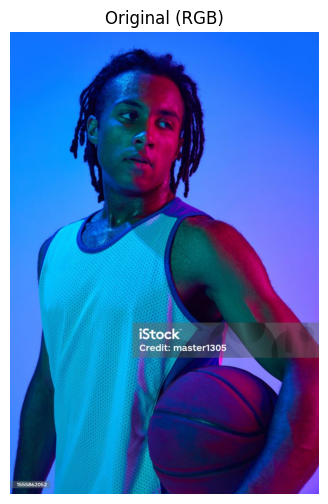

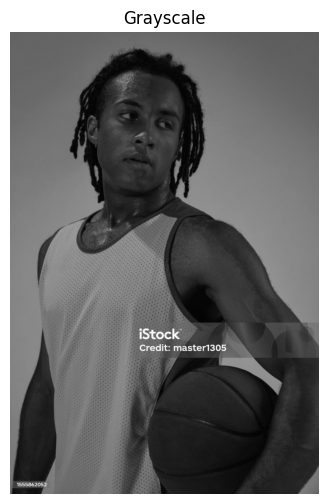

In [18]:
# Upload ONE image
from google.colab import files
up = files.upload()
IMG= list(up.keys())[0]
# Basic libs
import cv2, numpy as np, matplotlib.pyplot as plt
# Read as RGB for viewing + make grayscale (math simple)
bgr = cv2.imread(IMG, cv2. IMREAD_COLOR)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
def show(img, title="", size=5, cmap=None):
    plt.figure(figsize=(size,size))
    if img.ndim==2:
        plt.imshow(img, cmap=cmap or "gray")
    else:
        plt.imshow(img)
    plt.title(title); plt.axis("off"); plt.show()
show(rgb, "Original (RGB)", 6)
show(gray, "Grayscale", 6, "gray")

**Task 1: Applying Correlation**

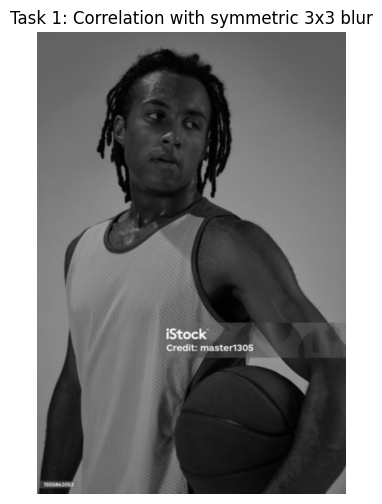

In [20]:
# 3x3 symmetric averaging-like kernel (sum = 1)
k_sym = np.array([[1,1,1],
[1,1,1],
[1,1,1]], dtype=np.float32)
k_sym = k_sym / k_sym.sum()
# Correlation (OpenCV filter2D does correlation)
corr_sym = cv2.filter2D (gray, ddepth=-1, kernel=k_sym)
show(corr_sym, "Task 1: Correlation with symmetric 3x3 blur", 6, "gray")

**Task 2: Applying Convolution**

Max diff (symmetric kernel) corr vs conv: 0


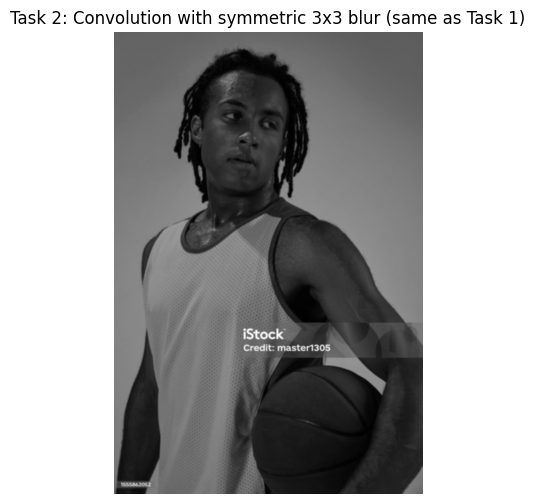

In [22]:
# Convolution correlation with flipped kernel
k_sym_flip = np.flipud (np.fliplr(k_sym)) # same as k_sym (symmetric)
conv_sym = cv2.filter2D (gray, ddepth=-1, kernel=k_sym_flip)
# Check difference
print("Max diff (symmetric kernel) corr vs conv:",
cv2.absdiff (corr_sym, conv_sym).max())
show(conv_sym, "Task 2: Convolution with symmetric 3x3 blur (same as Task 1)", 6, "gray")

Task 3 : Correlation and Convolution if kernel after flipped is same in convolution so no
change in output

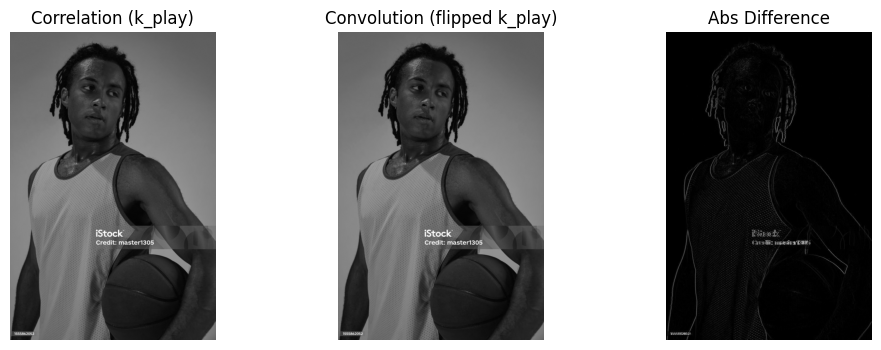

In [24]:
#Try putting the '1' at a different place:
k_play = np.array([[0,0,0],
                   [0,0,1], # Try 1 at a non-symmetric position (e.g., right side)
                   [0,0,0]], dtype=np.float32)

k_play_flip = np.flipud(np.fliplr(k_play))
play_corr = cv2.filter2D(gray, -1, k_play)
play_conv = cv2.filter2D(gray, -1, k_play_flip)
play_diff = cv2.absdiff(play_corr, play_conv)

plt.figure(figsize=(12,4))
for i, (img, title) in enumerate([
    (play_corr, "Correlation (k_play)"),
    (play_conv, "Convolution (flipped k_play)"),
    (play_diff, "Abs Difference")
], start=1):
    plt.subplot(1,3,i)
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.show()

Task 4: If kernel is changed after Flipping Then there should be difference in output of
Correlation and Convolution

min/max diff: 0 211


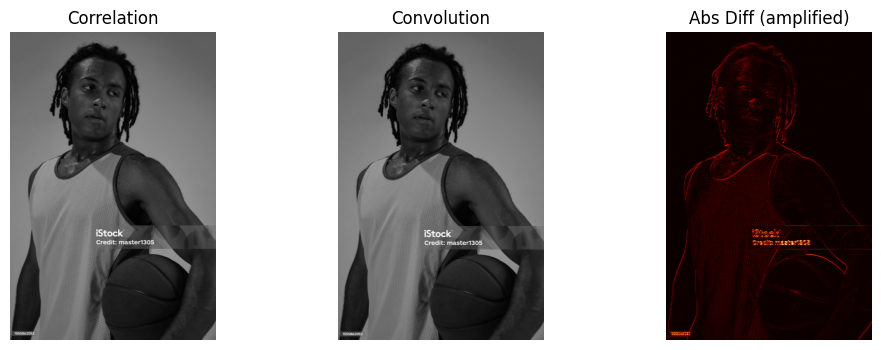

In [26]:
import numpy as np, cv2, matplotlib.pyplot as plt

# Your current gray image + kernel
K = np.array([[0,0,0],
              [0,0,0],
              [1,2,3]], np.float32) / 6.0

Kf = np.flipud(np.fliplr(K)) # convolution kernel
corr = cv2.filter2D(gray, -1, K)
conv = cv2.filter2D(gray, -1, Kf)
diff = cv2.absdiff(corr, conv)
print("min/max diff:", diff.min(), diff.max())

# Amplify difference so you can SEE it
amp = cv2.normalize(diff, None, 0, 255, cv2.NORM_MINMAX)
amp = cv2.convertScaleAbs(amp)

# uint8 for display
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(corr, cmap="gray")
plt.title("Correlation")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(conv, cmap="gray")
plt.title("Convolution")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(amp, cmap="hot")
plt.title("Abs Diff (amplified)")
plt.axis("off")

plt.show()